<a href="https://colab.research.google.com/github/tomturner846-dotcom/6BUIS017WRFMcourseworkTT/blob/main/cwdraftone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 6BUIS017W Coursework- Market analysis and stock segmentation using RFM.

In [1]:
# Import all relevant libraries and print all package versions.
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import scipy
import platform


print('Python', platform.python_version())
print('pandas', pd.__version__, '| numpy', np.__version__, '| yfinance', yf.__version__)
print('matplotlib', matplotlib.__version__, '| seaborn', sns.__version__)
print('scikit-learn', sklearn.__version__, '| scipy', scipy.__version__)

Python 3.13.18
pandas 2.2.3 | numpy 2.4.6 | yfinance 0.2.66
matplotlib 3.10.0 | seaborn 0.13.2
scikit-learn 1.6.1 | scipy 1.16.3


In [2]:
# Getting the s&p 500 ticker list from wikipedia.
# User agent used to avoid the 403 block.
from datetime import date

url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
sp500_df = table[0]

tickers = sp500_df['Symbol'].tolist()
tickers = [t.replace('.', '-') for t in tickers]
# Record retrieval date and then save the list as a CSV screenshot.
retrieval_date = date.today()
sp500_df.to_csv('sp500_tickers.csv', index=False)

print('Retrieval date:', retrieval_date)
print('Total tickers extracted:', len(tickers))
sp500_df[['Symbol', 'Security', 'GICS Sector']].head(10)

Retrieval date: 2026-11-23
Total tickers extracted: 503


,Symbol,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology
5,ADBE,Adobe Inc.,Information Technology
6,AMD,Advanced Micro Devices,Information Technology
7,AES,AES Corporation,Utilities
8,AFL,Aflac,Financials
9,A,Agilent Technologies,Health Care


In [3]:
# Download all daily close, adj close and volume for every ticker
# from the 1st of January 2021 to the 1st of January 2025.
start = '2021-01-01'
end = '2025-01-01'
# auto_adjust=False keeps both normal close for the RFM and adj close for
# returns, they are also saved as CSV's.
data = yf.download(tickers, start=start, end=end, auto_adjust=False)

df = data['Adj Close']      # adjusted prices
close = data['Close']       # daily prices
volume = data['Volume']     # daily volume

# Save a copy of the data
df.to_csv('adj_close.csv')
close.to_csv('close.csv')
volume.to_csv('volume.csv')

print('Shape:', df.shape)
df.head()

[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['VYLR', 'Q', 'SNDK', 'FDXF', 'HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Shape: (1005, 503)


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-04,114.009125,125.537102,84.219131,139.149994,97.269707,33.186359,232.029327,485.339996,132.622574,42.189487,...,26.124498,102.852112,54.757389,33.042759,93.015892,221.160004,95.016197,141.603348,378.130005,152.952042
2021-01-05,114.941254,127.089218,85.090019,148.300003,98.473183,33.319485,233.350281,485.690002,134.993134,43.010101,...,26.371332,106.017517,54.223648,34.635189,92.903938,229.750000,95.025169,144.053436,380.570007,154.017883
2021-01-06,118.093231,122.811195,84.354980,142.770004,98.268166,34.783871,235.901627,466.309998,135.601715,44.752827,...,26.506685,106.652519,55.424541,35.518978,96.822754,226.889999,95.545937,148.158386,394.820007,156.280502
2021-01-07,121.235596,127.001938,85.257790,151.270004,99.222054,34.460564,238.127258,477.739990,141.332703,44.355228,...,26.761484,105.594185,54.340420,35.797649,101.217415,239.479996,94.818672,147.280060,409.100006,156.140259
2021-01-08,122.100456,128.098114,85.705208,149.770004,99.498421,34.650742,238.995834,485.100006,142.359055,44.473660,...,26.578350,104.901451,54.840771,36.195763,100.191055,241.449997,96.210403,146.956482,405.470001,157.178070


In [4]:
# Downlaods the ^gspc for the same time period as the benchmark for the beta
market_prices = yf.download("^GSPC", start=start, end=end, auto_adjust=False)["Adj Close"]
market_prices.to_csv('gspc.csv')
# price index with no dividends
print('Benchmark shape:', market_prices.shape)
market_prices.head()

[*********************100%***********************]  1 of 1 completed

Benchmark shape: (1005, 1)


Ticker,^GSPC
Date,
2021-01-04,3700.649902
2021-01-05,3726.860107
2021-01-06,3748.139893
2021-01-07,3803.790039
2021-01-08,3824.679932


In [5]:
# Provenance check which confirms the retrieval date and the
# first last dates alongside the number of trading days.
# No data after the end date.
print('Ticker list retrieved:', retrieval_date)
print('Shares: first date', df.index.min().date(), '| last date', df.index.max().date())
print('Benchmark: first date', market_prices.index.min().date(), '| last date', market_prices.index.max().date())
print('Trading days - shares:', len(df), '| benchmark:', len(market_prices))
print('Same trading dates for shares and benchmark:', df.index.equals(market_prices.index))
print('No data after end date:', df.index.max() < pd.Timestamp(end))

Ticker list retrieved: 2026-11-23
Shares: first date 2021-01-04 | last date 2024-12-31
Benchmark: first date 2021-01-04 | last date 2024-12-31
Trading days - shares: 1005 | benchmark: 1005
Same trading dates for shares and benchmark: True
No data after end date: True


In [6]:
# Survivorship cell - how many of the s&p 500 members joined after
# the 1st Jan 2021.
sp500_df['Date added'] = pd.to_datetime(sp500_df['Date added'], errors='coerce')
added = sp500_df[sp500_df['Date added'] >= start]
print('Current members added on/after', start, ':', len(added))

Current members added on/after 2021-01-01 : 89


Data validation and re-alignment 1.2.

In [7]:
# Transpose data so each ticker is shown as a row to enable row by row checks.
df1 = df.T

# Remove all tickers with 0 pricing data such as failed downloads or
# companies not trading in the period.
before = df1.shape[0]
no_data = df1.index[df1.isna().all(axis=1)].tolist()
df1 = df1.dropna(how='all')
# No missing prices filled
print('Before:', before)
print('After:', df1.shape[0])
print('Tickers removed (no data):', no_data)

Before: 503
After: 498
Tickers removed (no data): ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


In [8]:
# Check for all duplicate trading dates in shares and benchmark.
print('Duplicate dates - shares:', df1.columns.duplicated().sum())
print('Duplicate dates - benchmark:', market_prices.index.duplicated().sum())

Duplicate dates - shares: 0
Duplicate dates - benchmark: 0


In [9]:
# Only keeping tickers with a price on every trading day to remove shares listed
# Every share now has a full period beta.
# Same history for RFM.
before = df1.shape[0]

min_cols = df1.shape[1]
removed = df1.index[df1.notna().sum(axis=1) < min_cols].tolist()
df1 = df1.dropna(thresh=min_cols)

print('Before:', before)
print('After:', df1.shape[0])
print('Tickers removed (incomplete history):', removed)

Before: 498
After: 488
Tickers removed (incomplete history): ['APP', 'CEG', 'COIN', 'EXE', 'GEHC', 'GEV', 'HOOD', 'RDDT', 'SOLV', 'VLTO']


In [10]:
# checks remaining shares for all non positive prices, missing close/volume
# and negative volume.
# even counts zero volume days.
remaining = df1.index

print('Non-positive Adj Close values:', (df1 <= 0).sum().sum())
print('Non-positive Close values:', (close[remaining] <= 0).sum().sum())
print('Missing Close values:', close[remaining].isna().sum().sum())
print('Missing Volume values:', volume[remaining].isna().sum().sum())
print('Negative Volume values:', (volume[remaining] < 0).sum().sum())
print('Zero-volume days:', (volume[remaining] == 0).sum().sum())

Non-positive Adj Close values: 0
Non-positive Close values: 0
Missing Close values: 0
Missing Volume values: 0
Negative Volume values: 0
Zero-volume days: 451


In [11]:
# Investigation of the zero volume days
# Counts all zero volume days by date and removes tickers which are affected.
zero_vol = (volume[remaining] == 0)

zero_by_date = zero_vol.sum(axis=1)
print('Dates with zero volume:')
print(zero_by_date[zero_by_date > 0])

zero_by_ticker = zero_vol.sum(axis=0)
print('\nNumber of tickers affected:', (zero_by_ticker > 0).sum())

Dates with zero volume:
Date
2021-01-05    1
2021-01-06    1
2021-01-07    1
2021-01-08    1
2021-01-12    2
             ..
2024-06-13    1
2024-06-17    1
2024-06-25    1
2024-07-02    1
2024-07-05    1
Length: 435, dtype: int64

Number of tickers affected: 2


In [12]:
# Show which tickers have 0 volume days.
zero_by_ticker[zero_by_ticker > 0]

,0
Ticker,
FERG,27
SW,424


In [13]:
#Getting rid of the zero volume days, would distort the RFM volume.
bad_volume = zero_by_ticker[zero_by_ticker > 0].index.tolist()
df1 = df1.drop(index=bad_volume)
# Excludes FERG and SW
print('Excluded (zero-volume days):', bad_volume)
print('Tickers remaining:', df1.shape[0])

Excluded (zero-volume days): ['FERG', 'SW']
Tickers remaining: 486


In [14]:
#Lists every daily close move which is above 40%
# so that an unadjusted split doent look like a crash.
remaining = df1.index
daily_change = close[remaining].pct_change(fill_method=None)
big = daily_change.abs() > 0.4

print('Daily Close moves above 40%:', big.sum().sum())
for t in remaining:
    for d in daily_change.index[big[t]]:
        print(t, d.date(), round(daily_change.loc[d, t] * 100, 1), '%')


Daily Close moves above 40%: 8
BE 2024-11-15 59.2 %
CVNA 2022-08-05 40.1 %
CVNA 2022-12-07 -42.9 %
CVNA 2023-01-12 46.0 %
CVNA 2023-06-08 56.0 %
CVNA 2023-07-19 40.2 %
DXCM 2024-07-26 -40.7 %
GL 2024-04-11 -53.1 %


In [15]:
# Shows NVIDIAs close during its split to prove a known split is accounted for.
close.loc['2024-06-05':'2024-06-12', 'NVDA']

,NVDA
Date,
2024-06-05,122.440002
2024-06-06,120.998001
2024-06-07,120.888000
2024-06-10,121.790001
2024-06-11,120.910004
2024-06-12,125.199997


In [16]:
# For dividends, comapres the adj close split with close for each share
remaining = df1.index
diff = (df[remaining] - close[remaining]).abs().max()

print('Shares where Adj Close differs from Close (dividend-adjusted):', (diff > 0.0001).sum())
print('Shares where Adj Close equals Close (no dividends in period):', (diff <= 0.0001).sum())
print('Days where Adj Close is ABOVE Close (should be 0):', (df[remaining] > close[remaining] + 0.0001).sum().sum())

Shares where Adj Close differs from Close (dividend-adjusted): 398
Shares where Adj Close equals Close (no dividends in period): 88
Days where Adj Close is ABOVE Close (should be 0): 0


In [17]:
# Weekly returns function, groups daily adjusted prices into ending weeks.
# Takes last available price for each week, weekly returns,
# this week / last week -1.
def calculate_weekly_returns(df1, shares=None):
    """Calculate weekly returns from df1 (tickers as rows, dates as columns)."""
    prices = df1 if shares is None else df1.loc[shares]

    prices = prices.T.copy()
    prices.index = pd.to_datetime(prices.index)
    prices = prices.sort_index()

    weekly_prices = prices.resample("W-FRI").last()
    return weekly_prices.pct_change(fill_method=None)

In [18]:
#Weekly returns
weekly_returns = calculate_weekly_returns(df1)

# Benchmark weekly returns
market_weekly_returns = market_prices.resample("W-FRI").last().pct_change(fill_method=None)
market_weekly_returns = pd.DataFrame({"^GSPC": market_weekly_returns.squeeze()})


In [19]:
# removes the incomplete final week(s).
weekly_returns = weekly_returns.loc[(weekly_returns.index >= start) & (weekly_returns.index < end)]
market_weekly_returns = market_weekly_returns.loc[(market_weekly_returns.index >= start) & (market_weekly_returns.index < end)]

In [20]:
# Alignment checks so that shares and benchmarks have identical weeks.
print('First week:', weekly_returns.index.min().date(), '| Last week:', weekly_returns.index.max().date())
print('Number of weeks:', len(weekly_returns))
print('Identical week labels:', weekly_returns.index.equals(market_weekly_returns.index))
print('Every week 7 days apart:', (weekly_returns.index.to_series().diff().dropna() == pd.Timedelta(days=7)).all())

days_per_week = market_prices.squeeze().resample('W-FRI').count().loc[weekly_returns.index]
print('Holiday-shortened weeks kept:', (days_per_week < 5).sum())

First week: 2021-01-08 | Last week: 2024-12-27
Number of weeks: 208
Identical week labels: True
Every week 7 days apart: True
Holiday-shortened weeks kept: 37


In [21]:
#Every removed ticker and reason put into a table.
exclusion_log = pd.concat([
    pd.DataFrame({'Ticker': no_data, 'Reason': 'No data returned for 2021-2024'}),
    pd.DataFrame({'Ticker': removed, 'Reason': 'Incomplete history (not trading for the whole period)'}),
    pd.DataFrame({'Ticker': bad_volume, 'Reason': 'Volume errors (zero-volume days)'}),
], ignore_index=True)

exclusion_log.to_csv('exclusion_log.csv', index=False)
print('Total excluded:', len(exclusion_log), '| Shares remaining:', df1.shape[0])

Total excluded: 17 | Shares remaining: 486


In [22]:
# 1.3.1 Arithmetic mean of each shares weekly reutns over the entire period.
mean_weekly_return = weekly_returns.mean()
weeks_used = weekly_returns.count()
# weekly observations.
returns_df = pd.DataFrame({'Mean_Weekly_Return': mean_weekly_return,
                           'Weekly_Observations': weeks_used})

print('Weekly observations per share:', weeks_used.min(), 'to', weeks_used.max())
returns_df.describe()



Weekly observations per share: 207 to 207


,Mean_Weekly_Return,Weekly_Observations
count,486.000000,486.0
mean,0.002857,207.0
std,0.002652,0.0
min,-0.004468,207.0
25%,0.001182,207.0
50%,0.002619,207.0
75%,0.004207,207.0
max,0.017772,207.0


In [23]:
# Independently checks AAPL return and compares to function.
p_prev = df.loc['2021-01-08', 'AAPL']
p_now = df.loc['2021-01-15', 'AAPL']

print('By hand:', p_now / p_prev - 1)
print('From function:', weekly_returns.loc['2021-01-15', 'AAPL'])

By hand: -0.037183095538102395
From function: -0.037183095538102395


In [24]:
#Beta function pairs each shares with the benchmarks by week.
def calculate_weekly_beta(weekly_returns, market_returns, min_weeks=52):
    """
    weekly_returns: DataFrame with weeks as rows and shares as columns.
    market_returns: Series of benchmark returns indexed by week.
    """
    if min_weeks < 2:
        raise ValueError("min_weeks must be at least 2.")
# Drops unmatched weeks then carries out the beta - covariance(share,market)
#/ variance(market)
    results = []

    for share in weekly_returns.columns:
        paired = pd.concat(
            [weekly_returns[share].rename("share"),
             market_returns.rename("market")],
            axis=1
        ).replace([np.inf, -np.inf], np.nan).dropna()

        variance = paired["market"].var(ddof=1)
        beta = np.nan

        if len(paired) >= min_weeks and variance > 0:
            beta = paired["share"].cov(paired["market"]) / variance

        results.append({
            "Share": share,
            "Beta": beta,
            "Paired_weeks": len(paired)
        })

    return pd.DataFrame(
        results, columns=["Share", "Beta", "Paired_weeks"]
    ).set_index("Share")

In [25]:
# Calculate the beta and return results
beta_df = calculate_weekly_beta(
    weekly_returns,
    market_weekly_returns["^GSPC"]
)

print('Paired weeks per share:', beta_df['Paired_weeks'].min(), 'to', beta_df['Paired_weeks'].max())
beta_df.describe()

Paired weeks per share: 207 to 207


,Beta,Paired_weeks
count,486.000000,486.0
mean,0.973695,207.0
std,0.407339,0.0
min,0.055453,207.0
25%,0.666600,207.0
50%,0.950610,207.0
75%,1.179538,207.0
max,3.778560,207.0


In [26]:
# Independent check that recalculates AAPLs beta a different way using NumPy
pair = pd.concat([weekly_returns['AAPL'], market_weekly_returns['^GSPC']], axis=1).dropna()
cov = np.cov(pair.iloc[:, 0], pair.iloc[:, 1])

print('By numpy:', cov[0, 1] / cov[1, 1])
print('From function:', beta_df.loc['AAPL', 'Beta'])

By numpy: 1.174836229919162
From function: 1.174836229919162


In [27]:
# Combination of the return and the beta.
risk_return = returns_df.join(beta_df)

risk_return.to_csv('risk_return_features.csv')
print('Shares:', len(risk_return))
risk_return.describe()

Shares: 486


,Mean_Weekly_Return,Weekly_Observations,Beta,Paired_weeks
count,486.000000,486.0,486.000000,486.0
mean,0.002857,207.0,0.973695,207.0
std,0.002652,0.0,0.407339,0.0
min,-0.004468,207.0,0.055453,207.0
25%,0.001182,207.0,0.666600,207.0
50%,0.002619,207.0,0.950610,207.0
75%,0.004207,207.0,1.179538,207.0
max,0.017772,207.0,3.778560,207.0


In [28]:
# Show the shares with the lowest and highest beta alongside mean weekly return.
print(risk_return.sort_values('Beta').iloc[[0, -1]])
print(risk_return.sort_values('Mean_Weekly_Return').iloc[[0, -1]])

        Mean_Weekly_Return  Weekly_Observations      Beta  Paired_weeks
Ticker                                                                 
GIS               0.001522                  207  0.055453           207
CVNA              0.010964                  207  3.778560           207
        Mean_Weekly_Return  Weekly_Observations      Beta  Paired_weeks
Ticker                                                                 
EL               -0.004468                  207  1.092522           207
SMCI              0.017772                  207  1.783662           207


In [29]:
shares = df1.index.tolist()   # RFM for each share

results = []

for ticker in shares:
    try:

        data = pd.DataFrame({"Close": close[ticker], "Volume": volume[ticker]})

        if data.empty:
            print(f"{ticker}: no data downloaded")
            continue

        data = data.sort_index()

        # Average of the previous 20 days, apart from the current day
        average_volume = data["Volume"].shift(1).rolling(20).mean()

        data["HighVolume"] = data["Volume"] > 2 * average_volume

        # Only do days with a complete volume baseline
        valid = data.loc[average_volume.notna()].copy()

        if len(valid) < 60:
            print(f"{ticker}: insufficient history")
            continue

        recent = valid.tail(60)
        high_volume_days = valid.loc[valid["HighVolume"]]

        # Recency in calendar days, latest high volume day to the
        # observation date.
        recency = (
            (valid.index[-1].date() - high_volume_days.index[-1].date()).days
            if not high_volume_days.empty
            else None
        )

        results.append({
            "Share": ticker,
            "AsOf": valid.index[-1].date(),
            "Recency": recency,
            "Frequency": int(recent["HighVolume"].sum()),
            "Monetary": round(
                (recent["Close"] * recent["Volume"]).sum(), 2
            )
        })

    except Exception as error:
        print(f"{ticker}: {error}")

output = pd.DataFrame(
    results,
    columns=["Share", "AsOf", "Recency", "Frequency", "Monetary"]
)

output["Recency"] = output["Recency"].astype("Int64")

print("Observation date(s):", output["AsOf"].unique())
print("Shares with RFM:", len(output), "| No high-volume event (Recency missing):", output["Recency"].isna().sum())
output.to_csv("rfm_485_shares.csv", index=False)
output.head(10)

Observation date(s): [datetime.date(2024, 12, 31)]
Shares with RFM: 486 | No high-volume event (Recency missing): 0


,Share,AsOf,Recency,Frequency,Monetary
0,A,2024-12-31,11,2,1.400180e+10
1,AAPL,2024-12-31,11,2,6.233034e+11
2,ABBV,2024-12-31,11,3,6.837054e+10
3,ABNB,2024-12-31,11,3,3.652850e+10
4,ABT,2024-12-31,11,1,3.523027e+10
5,ACGL,2024-12-31,11,4,1.196213e+10
6,ACN,2024-12-31,11,2,5.199430e+10
7,ADBE,2024-12-31,18,3,1.030403e+11
8,ADI,2024-12-31,36,1,3.849918e+10
9,ADM,2024-12-31,11,3,9.529780e+09


In [30]:
# Worked example: AAPL's RFM rebuilt by each step.
ex = pd.DataFrame({"Close": close["AAPL"], "Volume": volume["AAPL"]}).sort_index()
ex["Avg_Prev_20"] = ex["Volume"].shift(1).rolling(20).mean()
ex["Threshold"] = 2 * ex["Avg_Prev_20"]
ex["HighVolume"] = ex["Volume"] > ex["Threshold"]
ex["Traded_Value"] = ex["Close"] * ex["Volume"]

last60 = ex.tail(60)
obs_date = ex.index[-1]
last_event = ex.index[ex["HighVolume"]][-1]

print("Observation date:", obs_date.date())
print("Latest high-volume day:", last_event.date())
print("Recency =", (obs_date - last_event).days, "calendar days")
print("Frequency =", int(last60["HighVolume"].sum()), "high-volume days in last 60 sessions")
print("Monetary = $", round(last60["Traded_Value"].sum() / 1e9, 1), "billion")

# Show the high-volume days
last60[last60["HighVolume"]]

Observation date: 2024-12-31
Latest high-volume day: 2024-12-20
Recency = 11 calendar days
Frequency = 2 high-volume days in last 60 sessions
Monetary = $ 623.3 billion


,Close,Volume,Avg_Prev_20,Threshold,HighVolume,Traded_Value
Date,,,,,,
2024-11-25,232.869995,90152800,43820740.0,87641480.0,True,2.099388e+10
2024-12-20,254.490005,147495300,45004605.0,90009210.0,True,3.753608e+10


In [31]:
# Check the baseline (20 Dec2024) is the mean of the lat 20 sessions before it.
day = pd.Timestamp("2024-12-20")
pos = ex.index.get_loc(day)

prev20 = ex["Volume"].iloc[pos - 20:pos]
print("Baseline window:", prev20.index[0].date(), "to", prev20.index[-1].date())
print("Mean of previous 20 sessions (by hand):", prev20.mean())
print("Avg_Prev_20 from code:", ex.loc[day, "Avg_Prev_20"])
print("If the day itself were wrongly included:", ex["Volume"].iloc[pos - 19:pos + 1].mean())

Baseline window: 2024-11-21 to 2024-12-19
Mean of previous 20 sessions (by hand): 45004605.0
Avg_Prev_20 from code: 45004605.0
If the day itself were wrongly included: 50273955.0


In [32]:
# 1.5 Final feature table: one row per included share
features = risk_return.join(output.set_index("Share")[["Recency", "Frequency", "Monetary"]])
features = features.join(sp500_df.set_index(sp500_df["Symbol"].str.replace(".", "-", regex=False))[["Security", "GICS Sector"]])

# History check: every share needs at least 20 + 60 = 80 sessions
sessions = volume[features.index].notna().sum()
print("Sessions per share:", sessions.min(), "to", sessions.max(), "(need at least 80)")
print("60-session window:", ex.tail(60).index[0].date(), "to", ex.tail(60).index[-1].date())
print("Shares in feature table:", len(features))

features.to_csv("feature_table.csv")
features[["Mean_Weekly_Return", "Beta", "Recency", "Frequency", "Monetary"]].describe()

Sessions per share: 1005 to 1005 (need at least 80)
60-session window: 2024-10-07 to 2024-12-31
Shares in feature table: 486


,Mean_Weekly_Return,Beta,Recency,Frequency,Monetary
count,486.000000,486.000000,486.0,486.000000,4.860000e+02
mean,0.002857,0.973695,20.407407,2.989712,3.940419e+10
std,0.002652,0.407339,21.342438,1.330800,1.291388e+11
min,-0.004468,0.055453,4.0,0.000000,1.297483e+09
25%,0.001182,0.666600,11.0,2.000000,1.019517e+10
50%,0.002619,0.950610,11.0,3.000000,1.668382e+10
75%,0.004207,1.179538,14.75,4.000000,3.227689e+10
max,0.017772,3.778560,222.0,8.000000,1.847697e+12


In [33]:
# 2.1 Two separate feature matrices (same 486 shares in both)
risk_features = features[["Mean_Weekly_Return", "Beta"]].copy()
rfm_features = features[["Recency", "Frequency", "Monetary"]].copy()

print("Risk/return matrix:", risk_features.shape)
print("RFM matrix:", rfm_features.shape)
print("Same shares in both:", risk_features.index.equals(rfm_features.index))
print("Missing values:", risk_features.isna().sum().sum() + rfm_features.isna().sum().sum())

# Skewness of each feature (0 = symmetric; above about 1 = strongly right-skewed)
print("\nSkewness:")
print(features[["Mean_Weekly_Return", "Beta", "Recency", "Frequency", "Monetary"]].skew().round(2))

Risk/return matrix: (486, 2)
RFM matrix: (486, 3)
Same shares in both: True
Missing values: 0

Skewness:
Mean_Weekly_Return     0.87
Beta                    1.1
Recency                3.65
Frequency              0.42
Monetary              11.68
dtype: Float64


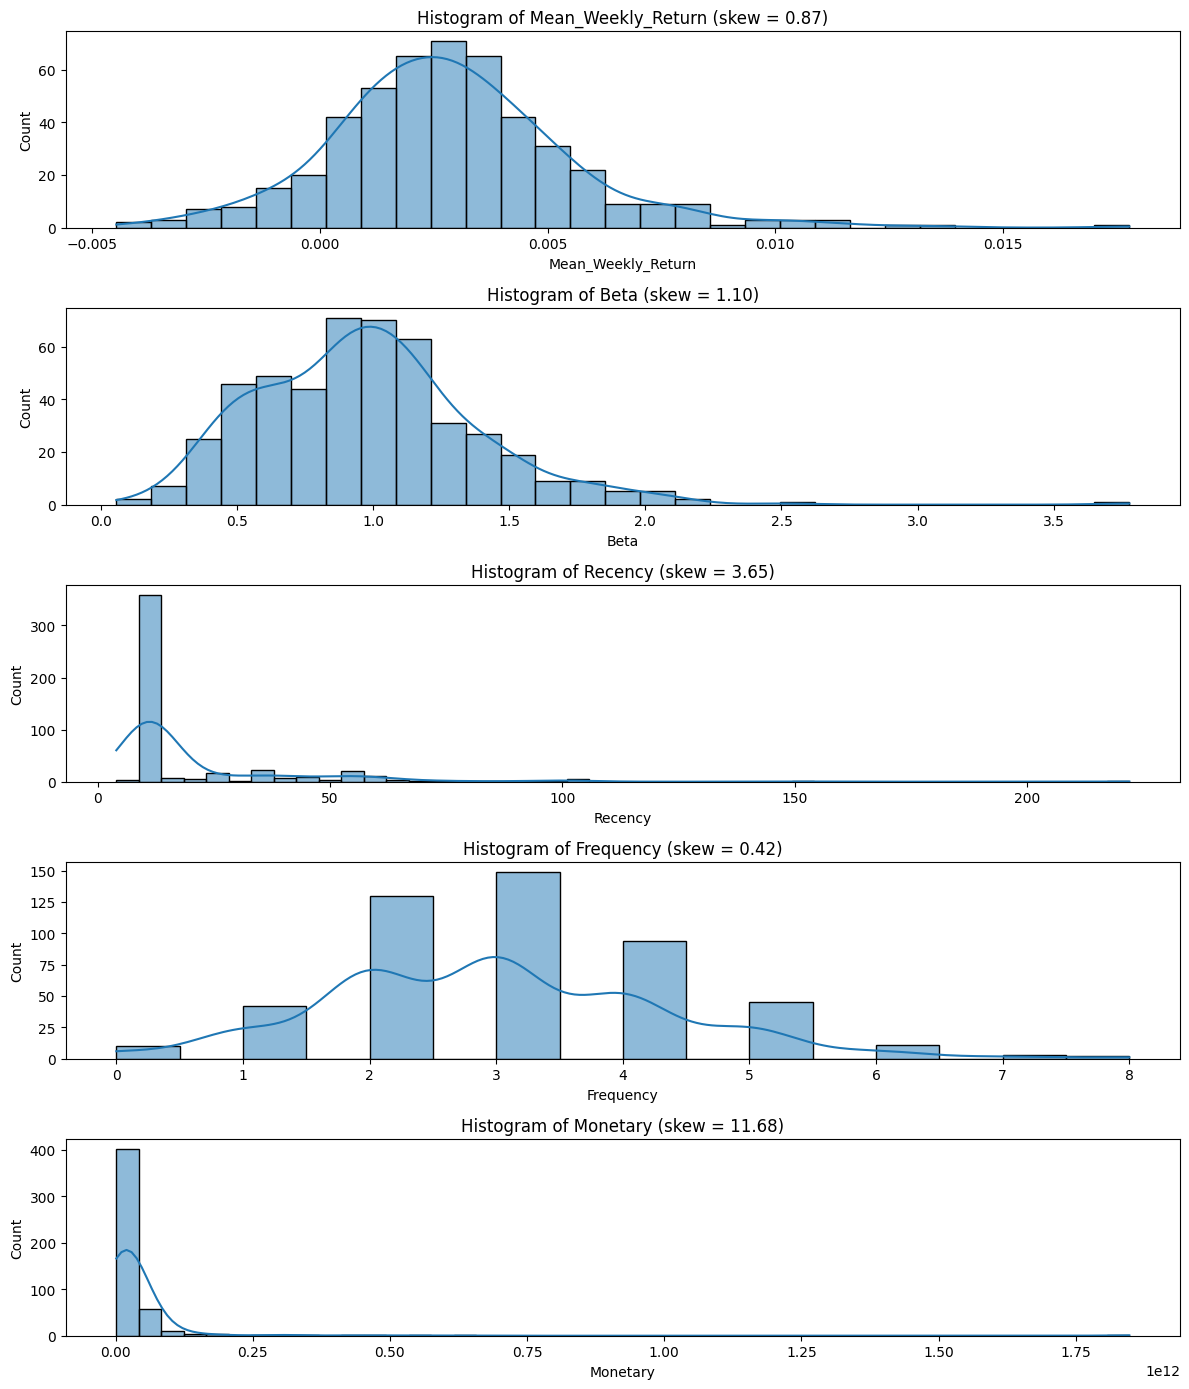

In [34]:
# Plot distributions of all five features
plt.figure(figsize=(12, 14))
for i, col in enumerate(["Mean_Weekly_Return", "Beta", "Recency", "Frequency", "Monetary"], start=1):
    plt.subplot(5, 1, i)
    sns.histplot(features[col], kde=True)
    plt.title(f"Histogram of {col} (skew = {features[col].skew():.2f})")
plt.tight_layout()
plt.savefig("feature_histograms.png", dpi=150)
plt.show()


Outliers per feature:
Mean_Weekly_Return     15
Beta                   10
Recency               115
Frequency               2
Monetary               45
dtype: Int64
Mean_Weekly_Return - largest 3: ['SMCI', 'NVDA', 'VRT']
Beta - largest 3: ['CVNA', 'XYZ', 'COHR']
Recency - largest 3: ['NVDA', 'WEC', 'CB']
Frequency - largest 3: ['CI', 'HSY', 'FOXA']
Monetary - largest 3: ['TSLA', 'NVDA', 'AAPL']


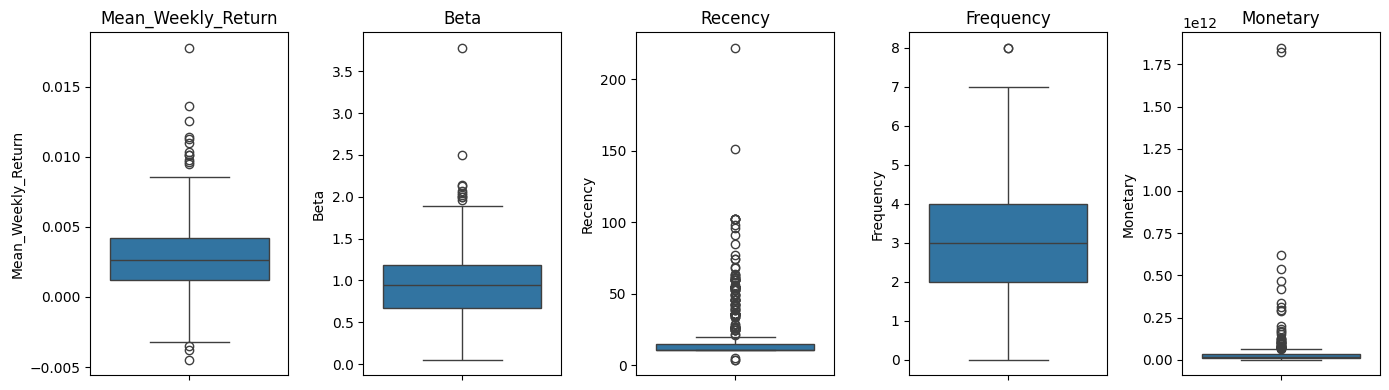

In [35]:
# 2.1 Step 3: outliers using the IQR rule
cols = ["Mean_Weekly_Return", "Beta", "Recency", "Frequency", "Monetary"]
q1, q3 = features[cols].quantile(0.25), features[cols].quantile(0.75)
iqr = q3 - q1
is_outlier = (features[cols] < q1 - 1.5 * iqr) | (features[cols] > q3 + 1.5 * iqr)

print("Outliers per feature:")
print(is_outlier.sum())
for col in cols:
    print(col, "- largest 3:", features[col].nlargest(3).index.tolist())

plt.figure(figsize=(14, 4))
for i, col in enumerate(cols, start=1):
    plt.subplot(1, 5, i)
    sns.boxplot(y=features[col])
    plt.title(col)
plt.tight_layout()
plt.savefig("feature_boxplots.png", dpi=150)
plt.show()

In [36]:
# 2.1 Step 4: transformations
rfm_prepared = rfm_features.copy()
rfm_prepared["Monetary"] = np.log1p(rfm_prepared["Monetary"])   # required
rfm_prepared["Recency"] = np.log1p(rfm_prepared["Recency"])     # skew 3.64, 115 IQR outliers

risk_prepared = risk_features.copy()                             # no transformation

print("RFM skew before:")
print(rfm_features.skew().round(2))
print("\nRFM skew after:")
print(rfm_prepared.skew().round(2))
print("\nRisk/return skew (unchanged):")
print(risk_prepared.skew().round(2))

RFM skew before:
Recency       3.65
Frequency     0.42
Monetary     11.68
dtype: Float64

RFM skew after:
Recency      1.58
Frequency    0.42
Monetary     1.08
dtype: Float64

Risk/return skew (unchanged):
Mean_Weekly_Return    0.87
Beta                  1.10
dtype: float64


In [37]:


# 2.1 Step 5: standardise each matrix separately ( K-means tutorial)
from sklearn.preprocessing import StandardScaler
risk_scaled = pd.DataFrame(StandardScaler().fit_transform(risk_prepared),
                           index=risk_prepared.index, columns=risk_prepared.columns)
rfm_scaled = pd.DataFrame(StandardScaler().fit_transform(rfm_prepared),
                          index=rfm_prepared.index, columns=rfm_prepared.columns)

# every feature now has mean 0 and standard deviation 1 (K-means tutorial's check)
print("Risk/return means:", risk_scaled.mean().round(2).tolist(), "| stds:", risk_scaled.std(ddof=0).round(2).tolist())
print("RFM means:", rfm_scaled.mean().round(2).tolist(), "| stds:", rfm_scaled.std(ddof=0).round(2).tolist())
print("Same 485 shares in both:", risk_scaled.index.equals(rfm_scaled.index), len(rfm_scaled))

Risk/return means: [0.0, 0.0] | stds: [1.0, 1.0]
RFM means: [-0.0, -0.0, -0.0] | stds: [1.0, 1.0, 1.0]
Same 485 shares in both: True 486


In [38]:
# 2.1 Step 6: how log1p changes the distances used by Ward and K-means
rfm_raw_scaled = pd.DataFrame(StandardScaler().fit_transform(rfm_features),
                              index=rfm_features.index, columns=rfm_features.columns)

for col in ["Monetary", "Recency"]:
    raw_sq = rfm_raw_scaled[col] ** 2
    log_sq = rfm_scaled[col] ** 2
    print(f"{col}:")
    print("  Largest z-score    - without log1p:", round(rfm_raw_scaled[col].abs().max(), 1),
          "| with log1p:", round(rfm_scaled[col].abs().max(), 1))
    print("  Top-5 share of squared distance - without log1p:", f"{raw_sq.nlargest(5).sum() / raw_sq.sum():.0%}",
          "| with log1p:", f"{log_sq.nlargest(5).sum() / log_sq.sum():.0%}")

Monetary:
  Largest z-score    - without log1p: 14.0 | with log1p: 4.8
  Top-5 share of squared distance - without log1p: 89% | with log1p: 17%
Recency:
  Largest z-score    - without log1p: 9.5 | with log1p: 4.2
  Top-5 share of squared distance - without log1p: 35% | with log1p: 12%


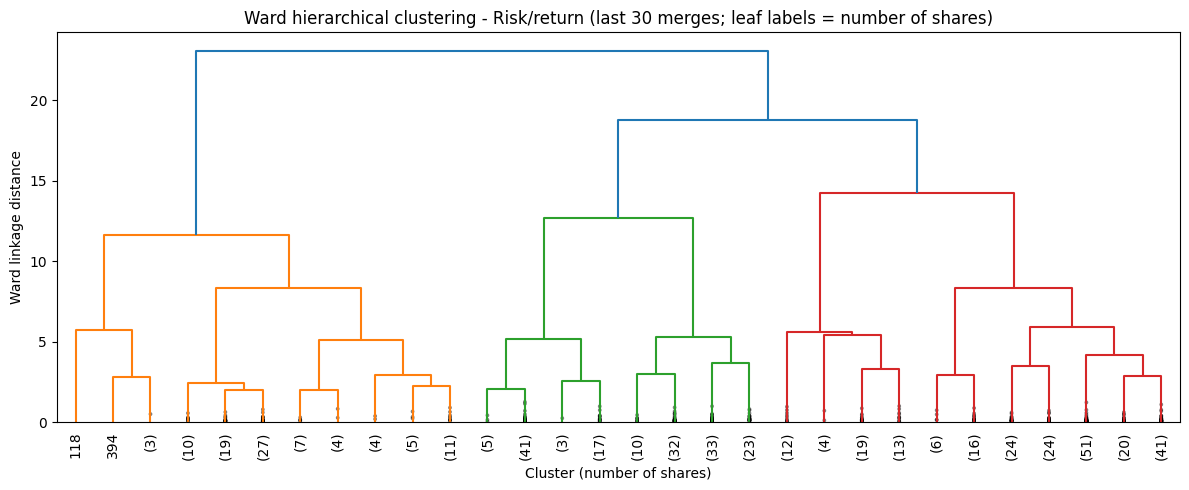

Risk/return - final merge heights:
  k=2: merge height 23.07 | jump from previous merge 4.27
  k=3: merge height 18.80 | jump from previous merge 4.59
  k=4: merge height 14.21 | jump from previous merge 1.54
  k=5: merge height 12.67 | jump from previous merge 1.07
  k=6: merge height 11.60 | jump from previous merge 3.26
  k=7: merge height 8.34 | jump from previous merge 0.03
  k=8: merge height 8.31 | jump from previous merge 2.38


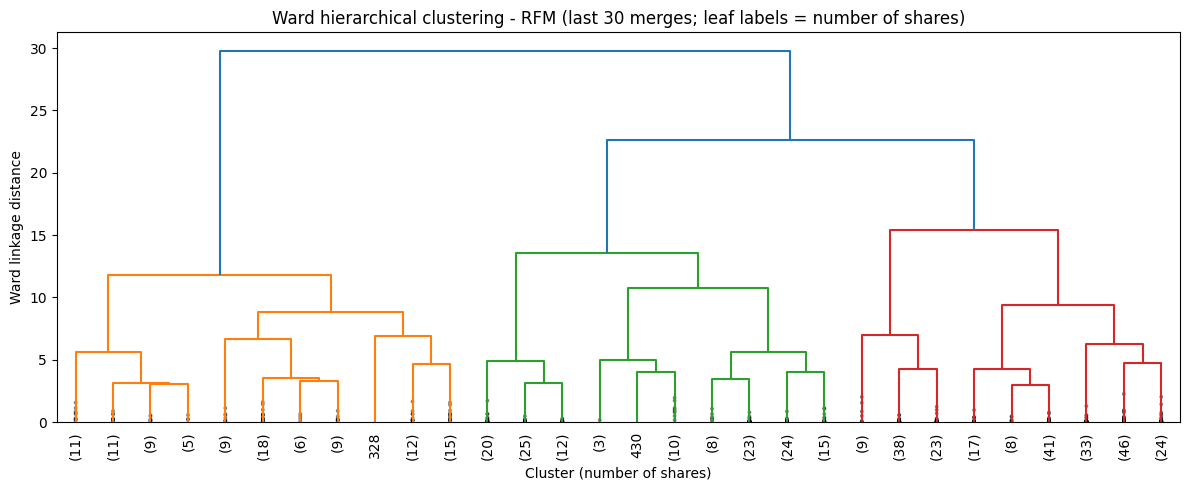

RFM - final merge heights:
  k=2: merge height 29.77 | jump from previous merge 7.18
  k=3: merge height 22.59 | jump from previous merge 7.17
  k=4: merge height 15.42 | jump from previous merge 1.87
  k=5: merge height 13.54 | jump from previous merge 1.76
  k=6: merge height 11.78 | jump from previous merge 1.02
  k=7: merge height 10.76 | jump from previous merge 1.41
  k=8: merge height 9.35 | jump from previous merge 0.50


In [39]:
# 2.2 Step 1: Ward linkage (Euclidean) and one dendrogram per matrix - as in Tutorial 3
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree

risk_hierarchy = linkage(risk_scaled, method="ward", metric="euclidean")
rfm_hierarchy = linkage(rfm_scaled, method="ward", metric="euclidean")

for name, hierarchy in [("Risk/return", risk_hierarchy), ("RFM", rfm_hierarchy)]:
    plt.figure(figsize=(12, 5))
    dendrogram(hierarchy, truncate_mode="lastp", p=30, leaf_rotation=90, show_contracted=True)
    plt.title(f"Ward hierarchical clustering - {name} (last 30 merges; leaf labels = number of shares)")
    plt.xlabel("Cluster (number of shares)")
    plt.ylabel("Ward linkage distance")
    plt.tight_layout()
    plt.savefig(f"dendrogram_{name.replace('/', '_').lower()}.png", dpi=150)
    plt.show()

    print(f"{name} - final merge heights:")
    for k in range(2, 9):
        height = hierarchy[-(k - 1), 2]
        gap = height - hierarchy[-k, 2]
        print(f"  k={k}: merge height {height:.2f} | jump from previous merge {gap:.2f}")

In [40]:
# 2.2 Step 2: compare Ward cluster counts k = 2..8 using silhouette scores and cluster sizes
from sklearn.metrics import silhouette_score

def ward_k_table(hierarchy, X):
    rows = []
    for k in range(2, 9):
        labels = cut_tree(hierarchy, n_clusters=k).ravel() + 1
        sizes = pd.Series(labels).value_counts().sort_index().tolist()
        rows.append({"k": k,
                     "Silhouette": round(silhouette_score(X, labels), 3),
                     "Smallest cluster": min(sizes),
                     "Cluster sizes": sizes})
    return pd.DataFrame(rows).set_index("k")

ward_risk_table = ward_k_table(risk_hierarchy, risk_scaled)
ward_rfm_table = ward_k_table(rfm_hierarchy, rfm_scaled)

print("Ward - Risk/return:")
print(ward_risk_table.to_string())
print("\nWard - RFM:")
print(ward_rfm_table.to_string())

Ward - Risk/return:
   Silhouette  Smallest cluster                     Cluster sizes
k                                                                
2       0.339                92                         [394, 92]
3       0.274                92                    [230, 92, 164]
4       0.282                48                [182, 92, 164, 48]
5       0.304                48             [182, 92, 98, 48, 66]
6       0.320                 5          [182, 87, 98, 48, 66, 5]
7       0.324                 5      [160, 87, 98, 48, 66, 22, 5]
8       0.321                 5  [160, 56, 98, 48, 66, 22, 31, 5]

Ward - RFM:
   Silhouette  Smallest cluster                      Cluster sizes
k                                                                 
2       0.402               106                         [380, 106]
3       0.335               106                    [239, 141, 106]
4       0.293                70                [169, 141, 70, 106]
5       0.286                57       

In [41]:
# 2.2 Step 3: profiles of candidate Ward solutions in original units (decides k with silhouette and sizes)
def ward_profile(hierarchy, original, k):
    labels = cut_tree(hierarchy, n_clusters=k).ravel() + 1
    profile = original.groupby(labels).mean()
    profile.insert(0, "Shares", pd.Series(labels).value_counts().sort_index().values)
    profile.index.name = "Cluster"
    return profile

rfm_original = rfm_features.assign(Monetary_bn=rfm_features["Monetary"] / 1e9).drop(columns="Monetary")

for k in [2, 3, 5]:
    print(f"\nWard Risk/return, k={k}:")
    print(ward_profile(risk_hierarchy, risk_features, k).round(4).to_string())

for k in [2, 3]:
    print(f"\nWard RFM, k={k}:")
    print(ward_profile(rfm_hierarchy, rfm_original, k).round(2).to_string())

# Singleton leaves seen in the dendrograms
print("\nRisk/return singletons:", risk_scaled.index[[118, 394]].tolist())
print("RFM singletons:", rfm_scaled.index[[328, 430]].tolist())


Ward Risk/return, k=2:
         Shares  Mean_Weekly_Return    Beta
Cluster                                    
1           394              0.0020  0.8979
2            92              0.0063  1.2981

Ward Risk/return, k=3:
         Shares  Mean_Weekly_Return    Beta
Cluster                                    
1           230              0.0015  1.1096
2            92              0.0063  1.2981
3           164              0.0029  0.6012

Ward Risk/return, k=5:
         Shares  Mean_Weekly_Return    Beta
Cluster                                    
1           182              0.0013  0.9728
2            92              0.0063  1.2981
3            98              0.0042  0.7104
4            48              0.0020  1.6280
5            66              0.0009  0.4390

Ward RFM, k=2:
         Shares  Recency  Frequency  Monetary_bn
Cluster                                         
1           380    11.47       3.16        38.67
2           106    52.43       2.40        42.04

Ward RFM, k

In [42]:
# 2.2 Step 4: final Ward solutions (k chosen from dendrogram, silhouette, sizes and profiles)
ward_risk_k = 3
ward_rfm_k = 3

features["Ward_Risk_Cluster"] = cut_tree(risk_hierarchy, n_clusters=ward_risk_k).ravel() + 1
features["Ward_RFM_Cluster"] = cut_tree(rfm_hierarchy, n_clusters=ward_rfm_k).ravel() + 1

print("Ward Risk/return sizes:", features["Ward_Risk_Cluster"].value_counts().sort_index().tolist())
print("Ward RFM sizes:", features["Ward_RFM_Cluster"].value_counts().sort_index().tolist())

features.to_csv("feature_table_with_clusters.csv")

Ward Risk/return sizes: [230, 92, 164]
Ward RFM sizes: [239, 141, 106]


K-means - Risk/return:
   Inertia  Silhouette  Smallest cluster                     Cluster sizes
k                                                                         
2    621.6       0.387               143                        [143, 343]
3    461.2       0.329               119                   [119, 202, 165]
4    371.6       0.326                41               [160, 41, 132, 153]
5    310.0       0.338                28           [165, 114, 28, 124, 55]
6    265.9       0.327                16        [55, 137, 119, 81, 16, 78]
7    227.2       0.329                 5     [78, 47, 5, 84, 105, 126, 41]
8    194.6       0.356                 5  [29, 141, 81, 77, 31, 43, 79, 5]

K-means - RFM:
   Inertia  Silhouette  Smallest cluster                      Cluster sizes
k                                                                          
2    999.5       0.415               102                         [102, 384]
3    742.5       0.343                90                  

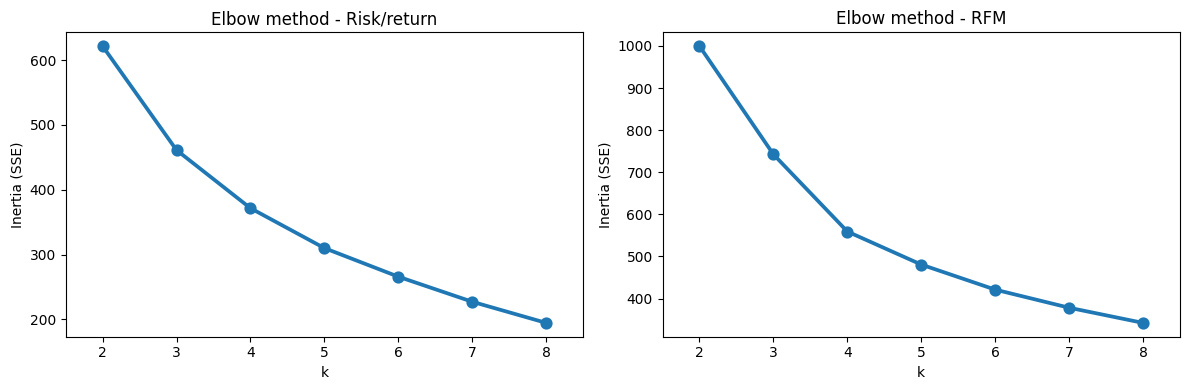

In [43]:
# 2.3 Step 1: K-means for k = 2..8 on both matrices (seeded, multiple initialisations)
from sklearn.cluster import KMeans

def kmeans_k_table(X):
    rows = []
    for k in range(2, 9):
        model = KMeans(n_clusters=k, n_init=20, random_state=42)
        labels = model.fit_predict(X) + 1
        sizes = pd.Series(labels).value_counts().sort_index().tolist()
        rows.append({"k": k,
                     "Inertia": round(model.inertia_, 1),
                     "Silhouette": round(silhouette_score(X, labels), 3),
                     "Smallest cluster": min(sizes),
                     "Cluster sizes": sizes})
    return pd.DataFrame(rows).set_index("k")

km_risk_table = kmeans_k_table(risk_scaled)
km_rfm_table = kmeans_k_table(rfm_scaled)

print("K-means - Risk/return:")
print(km_risk_table.to_string())
print("\nK-means - RFM:")
print(km_rfm_table.to_string())

# Elbow plots
plt.figure(figsize=(12, 4))
for i, (name, table) in enumerate([("Risk/return", km_risk_table), ("RFM", km_rfm_table)], start=1):
    plt.subplot(1, 2, i)
    sns.pointplot(x=table.index, y=table["Inertia"])
    plt.title(f"Elbow method - {name}")
    plt.xlabel("k")
    plt.ylabel("Inertia (SSE)")
plt.tight_layout()
plt.savefig("kmeans_elbow.png", dpi=150)
plt.show()

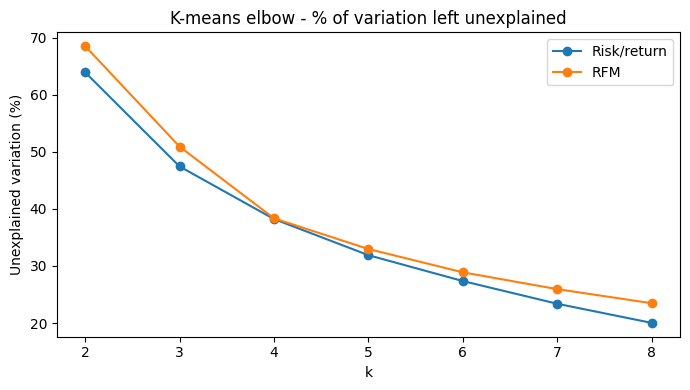

In [44]:
# Elbow plot on a common scale: inertia as % of total variation (shares x features after standardising)
plt.figure(figsize=(7, 4))
for name, table, X in [("Risk/return", km_risk_table, risk_scaled), ("RFM", km_rfm_table, rfm_scaled)]:
    plt.plot(table.index, table["Inertia"] / X.size * 100, marker="o", label=name)
plt.title("K-means elbow - % of variation left unexplained")
plt.xlabel("k")
plt.ylabel("Unexplained variation (%)")
plt.legend()
plt.tight_layout()
plt.savefig("kmeans_elbow.png", dpi=150)
plt.show()

In [45]:
# 2.3 Step 2: candidate K-means profiles (original units) and initialisation stability
from sklearn.metrics import adjusted_rand_score

def kmeans_profile(X, original, k):
    labels = KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(X) + 1
    profile = original.groupby(labels).mean()
    profile.insert(0, "Shares", pd.Series(labels).value_counts().sort_index().values)
    profile.index.name = "Cluster"
    return profile

for k in [2, 3]:
    print(f"\nK-means Risk/return, k={k}:")
    print(kmeans_profile(risk_scaled, risk_features, k).round(4).to_string())

for k in [3, 4]:
    print(f"\nK-means RFM, k={k}:")
    print(kmeans_profile(rfm_scaled, rfm_original, k).round(2).to_string())

# Initialisation checks 10 single-start runs with different seeds vs the 20-start solution
def init_check(name, X, k):
    best = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
    inertias, aris = [], []
    for seed in range(10):
        single = KMeans(n_clusters=k, n_init=1, random_state=seed).fit(X)
        inertias.append(single.inertia_)
        aris.append(adjusted_rand_score(best.labels_, single.labels_))
    print(f"{name} k={k}: best inertia {best.inertia_:.1f} | single-start inertia {min(inertias):.1f} to {max(inertias):.1f}"
          f" | agreement with best (ARI) {min(aris):.2f} to {max(aris):.2f}")

print()
init_check("Risk/return", risk_scaled, 3)
init_check("RFM", rfm_scaled, 3)
init_check("RFM", rfm_scaled, 4)


K-means Risk/return, k=2:
         Shares  Mean_Weekly_Return    Beta
Cluster                                    
1           143              0.0053  1.3505
2           343              0.0018  0.8166

K-means Risk/return, k=3:
         Shares  Mean_Weekly_Return    Beta
Cluster                                    
1           119              0.0060  1.3264
2           202              0.0026  0.6308
3           165              0.0009  1.1391

K-means RFM, k=3:
         Shares  Recency  Frequency  Monetary_bn
Cluster                                         
1           139    12.34       2.90        85.46
2            90    56.41       2.04        46.81
3           257    12.16       3.37        11.90

K-means RFM, k=4:
         Shares  Recency  Frequency  Monetary_bn
Cluster                                         
1           120    13.42       4.55        14.80
2           194    11.28       2.36        15.01
3            82    12.89       3.26       124.86
4            90    56.

In [46]:
# 2.3 Step 3: final K-means solutions (k chosen from silhouette, inertia, sizes and profiles)
km_risk_k = 3
km_rfm_k = 4

features["KM_Risk_Cluster"] = KMeans(n_clusters=km_risk_k, n_init=20, random_state=42).fit_predict(risk_scaled) + 1
features["KM_RFM_Cluster"] = KMeans(n_clusters=km_rfm_k, n_init=20, random_state=42).fit_predict(rfm_scaled) + 1

print("K-means Risk/return sizes:", features["KM_Risk_Cluster"].value_counts().sort_index().tolist())
print("K-means RFM sizes:", features["KM_RFM_Cluster"].value_counts().sort_index().tolist())

features.to_csv("feature_table_with_clusters.csv")

K-means Risk/return sizes: [119, 202, 165]
K-means RFM sizes: [120, 194, 82, 90]


In [47]:
 #2.4 Step 1: final cluster profiles in original units (mean values and number of shares)
def final_profile(cluster_col, cols):
    profile = features.groupby(cluster_col)[cols].mean()
    profile.insert(0, "Shares", features[cluster_col].value_counts().sort_index())
    if "Monetary" in cols:
        profile["Monetary"] = profile["Monetary"] / 1e9
        profile = profile.rename(columns={"Monetary": "Monetary_bn"})
    return profile

risk_cols = ["Mean_Weekly_Return", "Beta"]
rfm_cols = ["Recency", "Frequency", "Monetary"]

for col, cols in [("Ward_Risk_Cluster", risk_cols), ("KM_Risk_Cluster", risk_cols),
                  ("Ward_RFM_Cluster", rfm_cols), ("KM_RFM_Cluster", rfm_cols)]:
    print(f"\n{col}:")
    print(final_profile(col, cols).round(4).to_string())


Ward_Risk_Cluster:
                   Shares  Mean_Weekly_Return    Beta
Ward_Risk_Cluster                                    
1                     230              0.0015  1.1096
2                      92              0.0063  1.2981
3                     164              0.0029  0.6012

KM_Risk_Cluster:
                 Shares  Mean_Weekly_Return    Beta
KM_Risk_Cluster                                    
1                   119              0.0060  1.3264
2                   202              0.0026  0.6308
3                   165              0.0009  1.1391

Ward_RFM_Cluster:
                  Shares  Recency  Frequency  Monetary_bn
Ward_RFM_Cluster                                         
1                    239  11.1381     3.2845      11.6766
2                    141  12.0426     2.9362      84.4222
3                    106   52.434     2.3962      42.0397

KM_RFM_Cluster:
                Shares  Recency  Frequency  Monetary_bn
KM_RFM_Cluster                                    

In [48]:
# 2.4 Step 2: compare Ward and K-means memberships on the same 486 shares
print("Adjusted Rand index (1 = identical groupings, 0 = no better than chance):")
print("  Risk/return:", round(adjusted_rand_score(features["Ward_Risk_Cluster"], features["KM_Risk_Cluster"]), 3))
print("  RFM:", round(adjusted_rand_score(features["Ward_RFM_Cluster"], features["KM_RFM_Cluster"]), 3))

print("\nRisk/return - Ward (rows) vs K-means (columns):")
print(pd.crosstab(features["Ward_Risk_Cluster"], features["KM_Risk_Cluster"]))
print("\nRFM - Ward (rows) vs K-means (columns):")
print(pd.crosstab(features["Ward_RFM_Cluster"], features["KM_RFM_Cluster"]))

Adjusted Rand index (1 = identical groupings, 0 = no better than chance):
  Risk/return: 0.516
  RFM: 0.419

Risk/return - Ward (rows) vs K-means (columns):
KM_Risk_Cluster     1    2    3
Ward_Risk_Cluster              
1                  16   54  160
2                  90    0    2
3                  13  148    3

RFM - Ward (rows) vs K-means (columns):
KM_RFM_Cluster     1    2   3   4
Ward_RFM_Cluster                 
1                 93  146   0   0
2                 14   46  81   0
3                 13    2   1  90


PCA variance explained: PC1 44%, PC2 34%, total 77%
PCA loadings (how each feature builds the components):
     Recency  Frequency  Monetary
PC1     0.71      -0.65      0.27
PC2     0.03       0.41      0.91


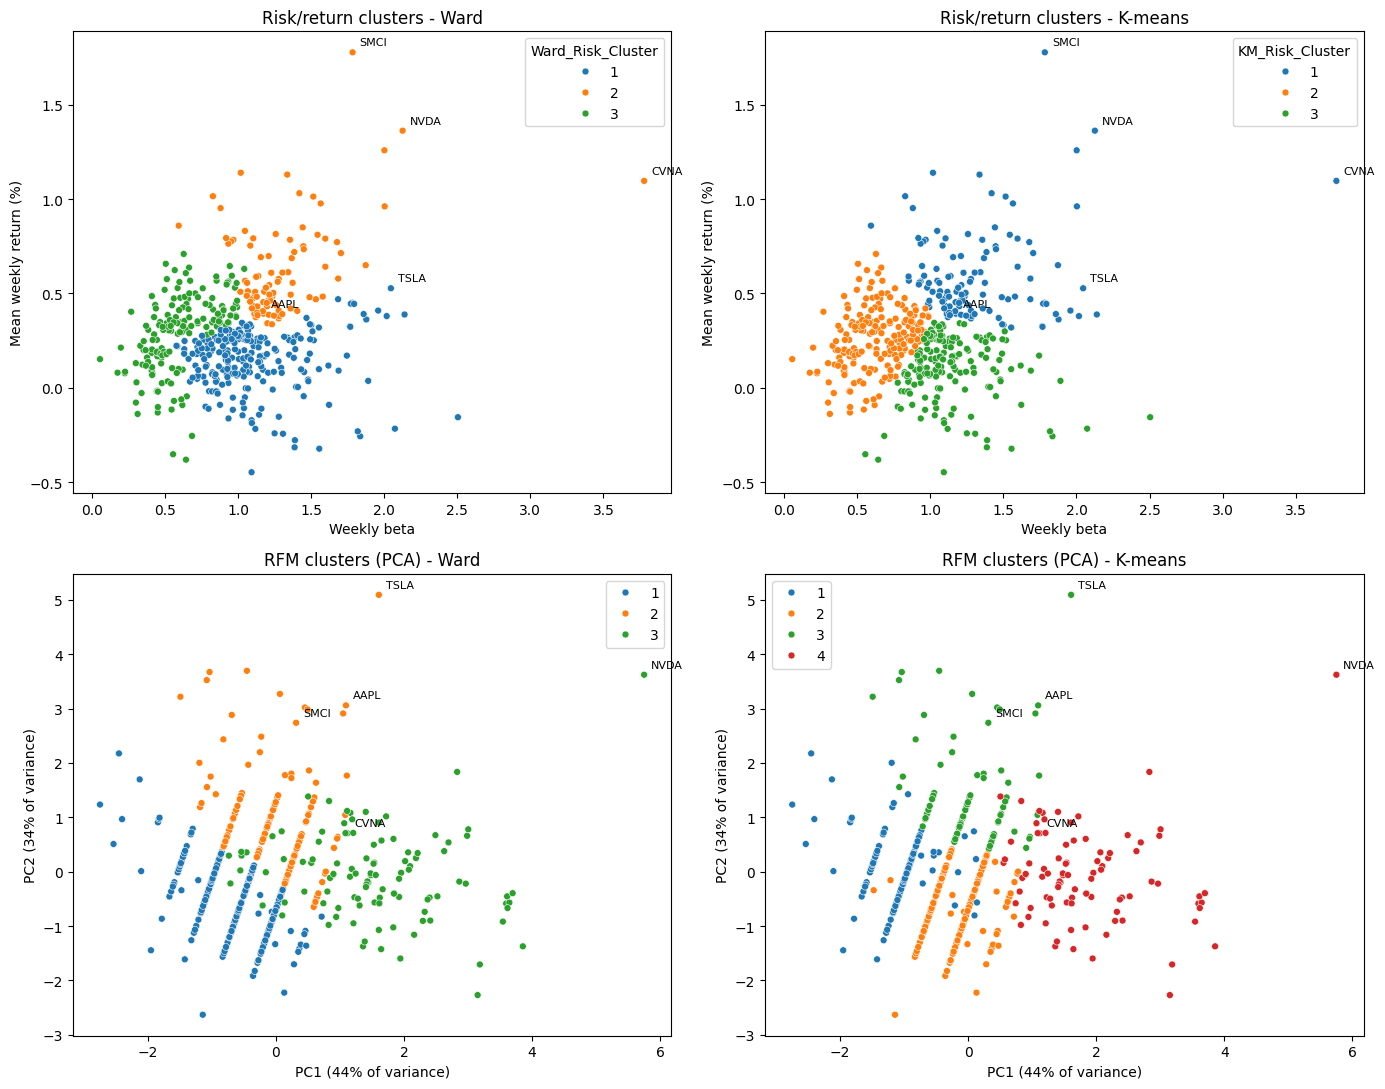

In [49]:
# 2.4 Step 3: labelled 2D plots
# Risk/return already has 2 features -> plot in original units, no reduction needed
# RFM has 3 features -> PCA reduces the standardised features to 2 components
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
rfm_2d = pca.fit_transform(rfm_scaled)
explained = pca.explained_variance_ratio_
print("PCA variance explained: PC1 {:.0%}, PC2 {:.0%}, total {:.0%}".format(explained[0], explained[1], explained.sum()))
print("PCA loadings (how each feature builds the components):")
print(pd.DataFrame(pca.components_, columns=rfm_scaled.columns, index=["PC1", "PC2"]).round(2))

highlight = ["CVNA", "SMCI", "NVDA", "TSLA", "AAPL"]

plt.figure(figsize=(14, 11))
for i, col in enumerate(["Ward_Risk_Cluster", "KM_Risk_Cluster"], start=1):
    plt.subplot(2, 2, i)
    sns.scatterplot(x=features["Beta"], y=features["Mean_Weekly_Return"] * 100,
                    hue=features[col], palette="tab10", s=25)
    for t in highlight:
        plt.annotate(t, (features.loc[t, "Beta"], features.loc[t, "Mean_Weekly_Return"] * 100),
                     xytext=(5, 5), textcoords="offset points", fontsize=8)
    plt.xlabel("Weekly beta")
    plt.ylabel("Mean weekly return (%)")
    plt.title(f"Risk/return clusters - {'Ward' if 'Ward' in col else 'K-means'}")

for i, col in enumerate(["Ward_RFM_Cluster", "KM_RFM_Cluster"], start=3):
    plt.subplot(2, 2, i)
    sns.scatterplot(x=rfm_2d[:, 0], y=rfm_2d[:, 1], hue=features[col].values, palette="tab10", s=25)
    for t in highlight:
        pos = features.index.get_loc(t)
        plt.annotate(t, (rfm_2d[pos, 0], rfm_2d[pos, 1]), xytext=(5, 5), textcoords="offset points", fontsize=8)
    plt.xlabel(f"PC1 ({explained[0]:.0%} of variance)")
    plt.ylabel(f"PC2 ({explained[1]:.0%} of variance)")
    plt.title(f"RFM clusters (PCA) - {'Ward' if 'Ward' in col else 'K-means'}")

plt.tight_layout()
plt.savefig("cluster_plots_2d.png", dpi=150)
plt.show()

In [50]:
# 2.5.1 Correlations among R, F and log1p(M)
corr_data = features[["Recency", "Frequency"]].copy()
corr_data["LogMonetary"] = np.log1p(features["Monetary"])

print("Pearson correlations:")
print(corr_data.corr().round(2))
print("\nSpearman (rank) correlations - robustness check, less sensitive to skew and outliers:")
print(corr_data.corr(method="spearman").round(2))

corr_data.corr().round(3).to_csv("rfm_correlations.csv")

Pearson correlations:
             Recency  Frequency  LogMonetary
Recency         1.00      -0.35         0.15
Frequency      -0.35       1.00         0.01
LogMonetary     0.15       0.01         1.00

Spearman (rank) correlations - robustness check, less sensitive to skew and outliers:
             Recency  Frequency  LogMonetary
Recency         1.00      -0.20         0.14
Frequency      -0.20       1.00        -0.05
LogMonetary     0.14      -0.05         1.00


In [51]:
# 2.5.2 Repeat the selected Ward RFM solution with R and F only (same shares, same k, fresh scaling)
rf_scaled = pd.DataFrame(StandardScaler().fit_transform(rfm_prepared[["Recency", "Frequency"]]),
                         index=rfm_prepared.index, columns=["Recency", "Frequency"])

rf_hierarchy = linkage(rf_scaled, method="ward", metric="euclidean")
features["Ward_RF_Cluster"] = cut_tree(rf_hierarchy, n_clusters=ward_rfm_k).ravel() + 1

print("Shares:", len(rf_scaled), "| k:", ward_rfm_k)
print("Adjusted Rand index, Ward R+F+M vs Ward R+F:",
      round(adjusted_rand_score(features["Ward_RFM_Cluster"], features["Ward_RF_Cluster"]), 3))

print("\nWard R+F+M (rows) vs Ward R+F only (columns):")
print(pd.crosstab(features["Ward_RFM_Cluster"], features["Ward_RF_Cluster"]))

# Traded value profiles, does monetary mainly seperate liquidity
for col in ["Ward_RFM_Cluster", "Ward_RF_Cluster"]:
    profile = features.groupby(col).agg(Shares=("Monetary", "size"),
                                        Recency=("Recency", "mean"),
                                        Frequency=("Frequency", "mean"),
                                        Median_traded_value_bn=("Monetary", lambda m: m.median() / 1e9),
                                        Mean_traded_value_bn=("Monetary", lambda m: m.mean() / 1e9))
    print(f"\n{col} traded value profile:")
    print(profile.round(2).to_string())

features.to_csv("feature_table_with_clusters.csv")

Shares: 486 | k: 3
Adjusted Rand index, Ward R+F+M vs Ward R+F: 0.349

Ward R+F+M (rows) vs Ward R+F only (columns):
Ward_RF_Cluster    1    2    3
Ward_RFM_Cluster              
1                 66  173    0
2                 59   74    8
3                  0    5  101

Ward_RFM_Cluster traded value profile:
                  Shares  Recency  Frequency  Median_traded_value_bn  Mean_traded_value_bn
Ward_RFM_Cluster                                                                          
1                    239    11.14       3.28                   11.15                 11.68
2                    141    12.04       2.94                   42.01                 84.42
3                    106    52.43       2.40                   19.49                 42.04

Ward_RF_Cluster traded value profile:
                 Shares  Recency  Frequency  Median_traded_value_bn  Mean_traded_value_bn
Ward_RF_Cluster                                                                          
1             


Ward_Risk_Cluster - sector composition (% of cluster):
Ward_Risk_Cluster          1     2     3
GICS Sector                             
Communication Services   3.0   5.4   4.9
Consumer Discretionary  11.7  12.0   5.5
Consumer Staples         2.2   0.0  16.5
Energy                   0.0   4.3   9.8
Financials              13.5  14.1  18.3
Health Care             12.6   2.2  16.5
Industrials             19.1  22.8   7.9
Information Technology  18.7  31.5   1.2
Materials                7.0   3.3   2.4
Real Estate             10.0   3.3   2.4
Utilities                2.2   1.1  14.6


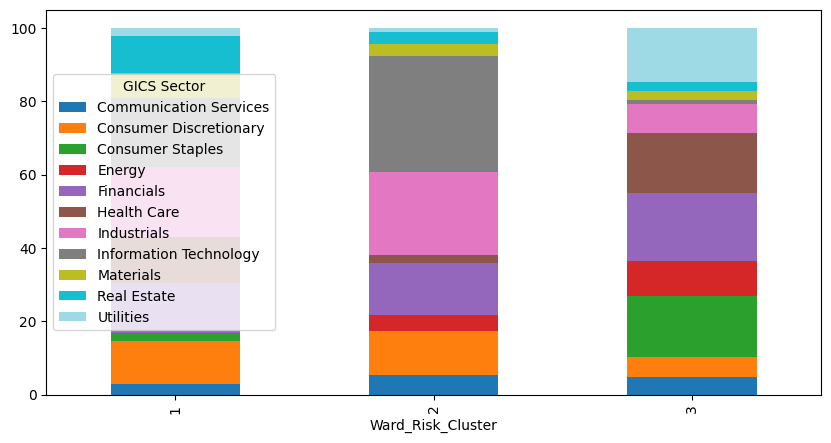


Ward_RFM_Cluster - sector composition (% of cluster):
Ward_RFM_Cluster           1     2     3
GICS Sector                             
Communication Services   2.9   6.4   3.8
Consumer Discretionary   7.5  12.1  11.3
Consumer Staples         5.9   7.1   7.5
Energy                   2.9   7.1   2.8
Financials              15.9  14.9  14.2
Health Care             10.9  14.9  10.4
Industrials             20.1  13.5  10.4
Information Technology   9.2  19.9  22.6
Materials                5.4   1.4   7.5
Real Estate             11.3   2.1   0.0
Utilities                7.9   0.7   9.4


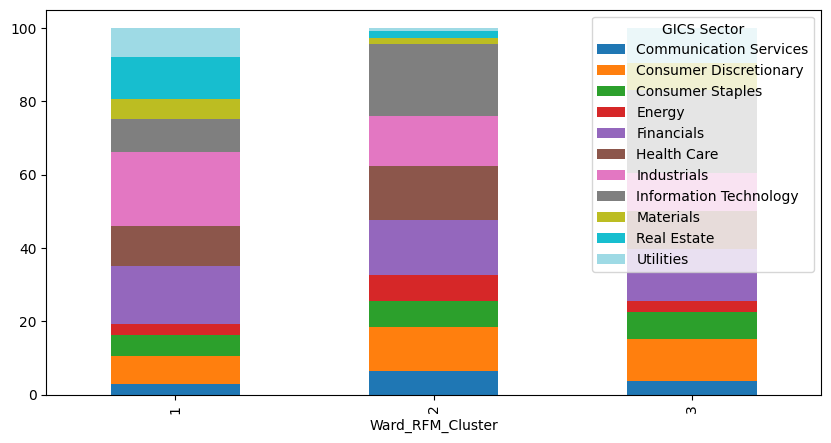

In [52]:
for col in ["Ward_Risk_Cluster", "Ward_RFM_Cluster"]:
    composition = pd.crosstab(features["GICS Sector"], features[col], normalize="columns") * 100
    print(f"\n{col} - sector composition (% of cluster):")
    print(composition.round(1).to_string())
    composition.T.plot(kind="bar", stacked=True, figsize=(10, 5), colormap="tab20")
    # title, y-axis label, legend, tight_layout
    plt.savefig(f"sector_composition_{col.lower()}.png", dpi=150)
    plt.show()

In [53]:
print(pd.crosstab(features["Ward_Risk_Cluster"], features["Ward_RFM_Cluster"]))
print("ARI risk/return vs RFM:", round(adjusted_rand_score(features["Ward_Risk_Cluster"], features["Ward_RFM_Cluster"]), 3))

Ward_RFM_Cluster     1   2   3
Ward_Risk_Cluster             
1                  129  53  48
2                   32  35  25
3                   78  53  33
ARI risk/return vs RFM: 0.026


In [54]:
!zip data_snapshot.zip *.csv *.png
from google.colab import files
files.download("data_snapshot.zip")

  adding: adj_close.csv (deflated 62%)
  adding: close.csv (deflated 77%)
  adding: exclusion_log.csv (deflated 77%)
  adding: feature_table.csv (deflated 56%)
  adding: feature_table_with_clusters.csv (deflated 58%)
  adding: gspc.csv (deflated 73%)
  adding: rfm_485_shares.csv (deflated 62%)
  adding: rfm_correlations.csv (deflated 38%)
  adding: risk_return_features.csv (deflated 55%)
  adding: sp500_tickers.csv (deflated 69%)
  adding: volume.csv (deflated 62%)
  adding: cluster_plots_2d.png (deflated 4%)
  adding: dendrogram_rfm.png (deflated 18%)
  adding: dendrogram_risk_return.png (deflated 19%)
  adding: feature_boxplots.png (deflated 17%)
  adding: feature_histograms.png (deflated 14%)
  adding: kmeans_elbow.png (deflated 9%)
  adding: sector_composition_ward_rfm_cluster.png (deflated 16%)
  adding: sector_composition_ward_risk_cluster.png (deflated 17%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>